In [3]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import optimize
%matplotlib inline

In [4]:
rng = np.random.default_rng(42)
n = 60

# Two overlapping groups of points, one per class
X0 = rng.normal(loc=[0.35, 0.35], scale=0.25, size=(n // 2, 2))
X1 = rng.normal(loc=[0.65, 0.65], scale=0.25, size=(n // 2, 2))

X = np.vstack([X0, X1])
y = np.array([0] * (n // 2) + [1] * (n // 2)).reshape(-1, 1)

data = np.hstack([X, y])
np.savetxt('logistic_regression_data.csv', data, delimiter=',')

In [5]:
print(np.loadtxt('logistic_regression_data.csv', delimiter=',').shape)

(60, 3)


In [6]:
X

array([[ 0.42617927,  0.09000397],
       [ 0.5376128 ,  0.58514118],
       [-0.1377588 ,  0.02445512],
       [ 0.3819601 ,  0.27093935],
       [ 0.34579971,  0.13673902],
       [ 0.56984949,  0.54444798],
       [ 0.36650767,  0.6318103 ],
       [ 0.46687734,  0.13517688],
       [ 0.4421877 ,  0.11027935],
       [ 0.56961258,  0.33751852],
       [ 0.30378441,  0.17976761],
       [ 0.65563533,  0.31136763],
       [ 0.24291804,  0.26196661],
       [ 0.4830773 ,  0.44136102],
       [ 0.45318315,  0.45770525],
       [ 0.8854119 ,  0.24839625],
       [ 0.22193932,  0.14655682],
       [ 0.50399486,  0.63224307],
       [ 0.32151314,  0.13996088],
       [ 0.1438797 ,  0.5126482 ],
       [ 0.53581354,  0.48578857],
       [ 0.18362257,  0.40804033],
       [ 0.37917145,  0.40467215],
       [ 0.56785719,  0.40589889],
       [ 0.51972839,  0.36689477],
       [ 0.42227985,  0.50782206],
       [-0.01428895,  0.2700822 ],
       [ 0.23240684,  0.19028054],
       [ 0.28121444,

<function matplotlib.pyplot.show(close=None, block=None)>

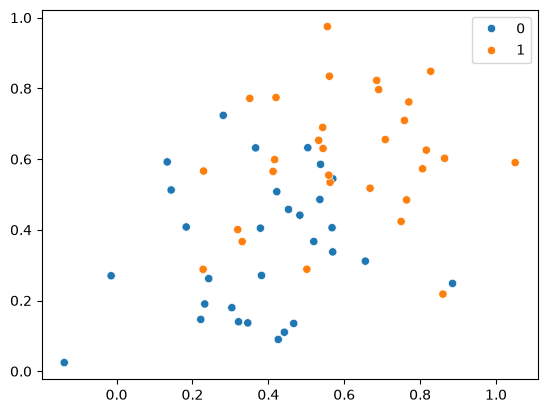

In [7]:
sns.scatterplot(x = X[:, 0], y = X[:, 1], hue=y.flatten())
plt.show

In [8]:
def sigmoid(z):
    return 1/(1 + np.exp(-z))

In [9]:
def loss(theta, X, y):
    h = sigmoid(np.dot(X, theta))
    cos = -(np.sum(y * np.log(h) + np.sum((1 - y) * np.log(1 - h)))/len(y))
    return cos

In [10]:
def grad(theta, X, y):
    h = sigmoid(np.dot(X, theta))
    grad = np.dot(X.T, (h - y)) / len(y)
    return grad

In [11]:
def expand_feature(x1, x2, power = 2):
    """
    Expands the features into polynomial features up to the given power.
    For example, if power=2, it will return [1, x1, x2, x1^2, x1*x2, x2^2].
    """
    new_x = np.ones((x1.shape[0], 1))
    for i in range(1, power + 1):
        for j in range(i + 1):
            new_x = np.append(new_x, ((x1 ** (i - j)) * (x2 ** j)).reshape(-1, 1), axis=1)
    return new_x

In [17]:
def predict(theta, X):
    return (sigmoid(np.dot(X, theta)) >= 0.5).flatten()

In [18]:
def gradient_descent(X, y, theta, alpha, num_iters):
    """
    Performs gradient descent to learn theta.
    Returns the final theta and the history of the loss function.
    """
    m = len(y)
    costs = []

    for _ in range(num_iters):
        h=sigmoid(np.dot(X, theta))
        theta -= alpha * np.dot(X.T, (h - y))/m
        costs.append(loss(theta, X, y))
    return theta, costs

In [19]:
data = np.loadtxt('logistic_regression_data.csv', delimiter=',', dtype=np.float64)
X, y = data[:, :-1], data[:, -1].reshape((-1, 1))

In [20]:
def logistic_regression(X, y, power=2, alpha=0.01, num_iters=100):
    X = expand_feature(X[:, 0], X[:, 1], power=power)
    theta = np.zeros((X.shape[1], 1))
    theta, costs = gradient_descent(X, y, theta, alpha, num_iters)
    predicted = predict(theta, X)
    return predicted, theta, costs

In [21]:
power, num_iters = 20, 20000
predicted, theta, costs = logistic_regression(X, y, power = power, alpha=0.6, num_iters=num_iters)

In [22]:
print('The accuracy is {:.2f}%'.format(sum(predicted == y.flatten())/len(y)*100))

The accuracy is 80.00%


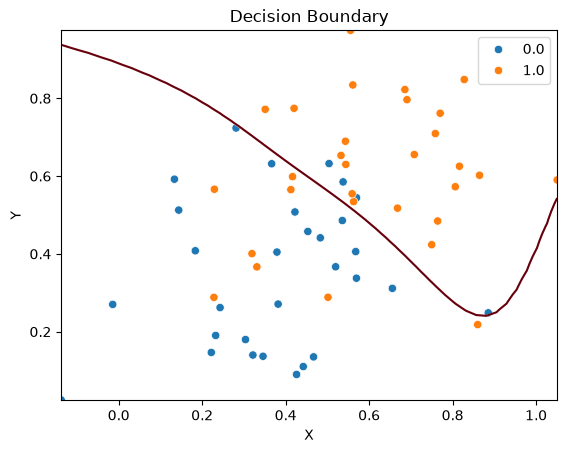

In [29]:
u = np.linspace(min(X[:, 0]), max(X[:, 0]), 50)
v = np.linspace(min(X[:, 1]), max(X[:, 1]), 50)

z = np.zeros((len(u), len(v)))

fz = np.zeros((len(u), len(v)))

for i in range(len(u)):
    for j in range(len(v)):
        z[i, j] = np.dot(expand_feature(u[i].reshape(1, -1), v[j].reshape(1, -1), power=power), theta).item()
z = np.transpose(z)

plt.contour(u, v, z, [0, 0.01], cmap='Reds')
sns.scatterplot(x = X[:, 0], y= X[:, 1], hue=y.flatten())
plt.title('Decision Boundary')
plt.xlabel('X')
plt.ylabel('Y')
plt.show()

In [30]:
#Regularization
def cost_reg(theta, X, y, lam=0):
    h = sigmoid(np.dot(X, theta))
    theta1 = theta.copy()
    theta1[0] = 0  # Do not regularize the bias term
    cos = -(np.sum(y * np.log(h) + np.sum((1 - y) * np.log(1 - h)))/len(y) + lam * np.sum(theta1 * theta1)/len(y))
    return cos 

In [31]:
def grad_reg(theta, X, y, lam=0):
    h = sigmoid(np.dot(X, theta))
    theta1 = theta.copy()
    theta1[0] = 0  # Do not regularize the bias term
    grad = (np.dot(X.T, (h - y)) + 2 * lam * theta1)/ len(y)
    return grad

In [32]:
def gradient_descent_reg(X, y, theta, alpha, num_iters = 100, lam=0):
    """
    Performs gradient descent to learn theta with regularization.
    Returns the final theta and the history of the loss function.
    """
    m = len(y)
    costs = []

    for _ in range(num_iters):
        h = sigmoid(np.dot(X, theta))
        theta1 = theta.copy()
        theta1[0] = 0  # Do not regularize the bias term
        theta -= alpha * (np.dot(X.T, (h - y)) + 2 * lam * np.r_[[[0]], theta[1:]]) / m
        costs.append(cost_reg(theta, X, y, lam))
    return theta, costs

In [33]:
def logistic_regression_reg(X, y, power=2, alpha=0.01, num_iters=100, lam=0):
    X = expand_feature(X[:, 0], X[:, 1], power=power)
    theta = np.zeros((X.shape[1], 1), dtype=np.float64)
    theta, costs = gradient_descent_reg(X, y, theta, alpha, num_iters, lam)
    predicted = predict(theta, X)
    return predicted, theta, costs

In [34]:
power, num_iters = 20, 20000
lam = 1
predicted, theta, costs = logistic_regression_reg(X, y, power = power, alpha=0.6, num_iters=num_iters, lam=lam)

In [35]:
print('The accuracy is {:.2f}%'.format(sum(predicted == y.flatten())/len(y)*100))

The accuracy is 80.00%


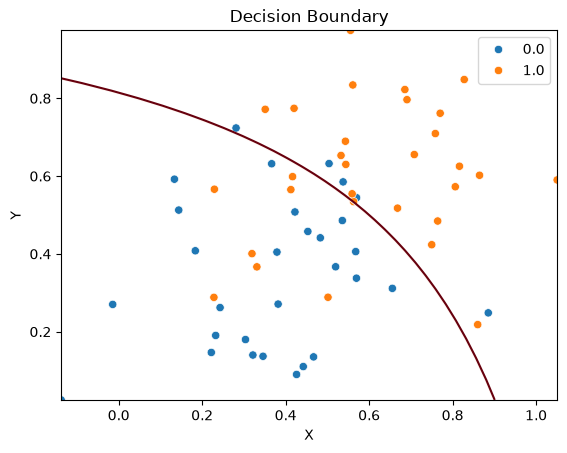

In [36]:
u = np.linspace(min(X[:, 0]), max(X[:, 0]), 50)
v = np.linspace(min(X[:, 1]), max(X[:, 1]), 50)

z = np.zeros((len(u), len(v)))


for i in range(len(u)):
    for j in range(len(v)):
        z[i, j] = np.dot(expand_feature(u[i].reshape(1, -1), v[j].reshape(1, -1), power=power), theta).item()
z = np.transpose(z)

plt.contour(u, v, z, [0, 0.01], cmap='Reds')
sns.scatterplot(x = X[:, 0], y= X[:, 1], hue=y.flatten())
plt.title('Decision Boundary')
plt.xlabel('X')
plt.ylabel('Y')
plt.show() 